# Preprocessing and EDA — PashuCare AI

In [1]:
import os
import sys
import glob
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid', palette='muted')

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "data")
IMAGE_DIR = os.path.join(DATA_DIR, "images")
SYMPTOM_CSV_PATH = os.path.join(DATA_DIR, "Cattle_Symptom_Master_Dataset.csv")
FIRST_AID_CSV_PATH = os.path.join(DATA_DIR, "Dataset3_Final_Preprocessed.csv")

print(f"Project Base Directory : {BASE_DIR}")
print(f"Data Directory         : {DATA_DIR} (Exists: {os.path.exists(DATA_DIR)})")
print(f"Image Directory        : {IMAGE_DIR} (Exists: {os.path.exists(IMAGE_DIR)})")
print(f"Symptom CSV Path       : {SYMPTOM_CSV_PATH} (Exists: {os.path.exists(SYMPTOM_CSV_PATH)})")
print(f"First-Aid CSV Path     : {FIRST_AID_CSV_PATH} (Exists: {os.path.exists(FIRST_AID_CSV_PATH)})")


Project Base Directory : c:\Users\KINGB\Downloads\Coding\SML Project
Data Directory         : c:\Users\KINGB\Downloads\Coding\SML Project\data (Exists: True)
Image Directory        : c:\Users\KINGB\Downloads\Coding\SML Project\data\images (Exists: True)
Symptom CSV Path       : c:\Users\KINGB\Downloads\Coding\SML Project\data\Cattle_Symptom_Master_Dataset.csv (Exists: True)
First-Aid CSV Path     : c:\Users\KINGB\Downloads\Coding\SML Project\data\Dataset3_Final_Preprocessed.csv (Exists: True)


## 2. Cattle image dataset

This part counts images by class and split, checks files for readability and exact duplicates, and displays a few valid images. It also shows the resize and normalization steps used before image-model training.

In [2]:
splits = ['train', 'valid', 'test']
image_records = []

for split in splits:
    split_dir = os.path.join(IMAGE_DIR, split)
    if not os.path.exists(split_dir):
        continue
    for class_name in os.listdir(split_dir):
        class_dir = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            if os.path.isfile(fpath):
                image_records.append({
                    'split': split,
                    'class': class_name,
                    'filename': fname,
                    'filepath': fpath,
                    'size_bytes': os.path.getsize(fpath)
                })

df_images = pd.DataFrame(image_records)
print(f"Total image files indexed: {len(df_images)}")

class_split_counts = pd.crosstab(df_images['class'], df_images['split'], margins=True, margins_name='Total')
print("\nImage Counts by Class and Split:")
display(class_split_counts)


Total image files indexed: 3884

Image Counts by Class and Split:


split,test,train,valid,Total
class,,,,
fmd,74,700,100,874
healthy,233,700,271,1204
lumpy skin,141,700,177,1018
mastitis,38,700,50,788
Total,486,2800,598,3884


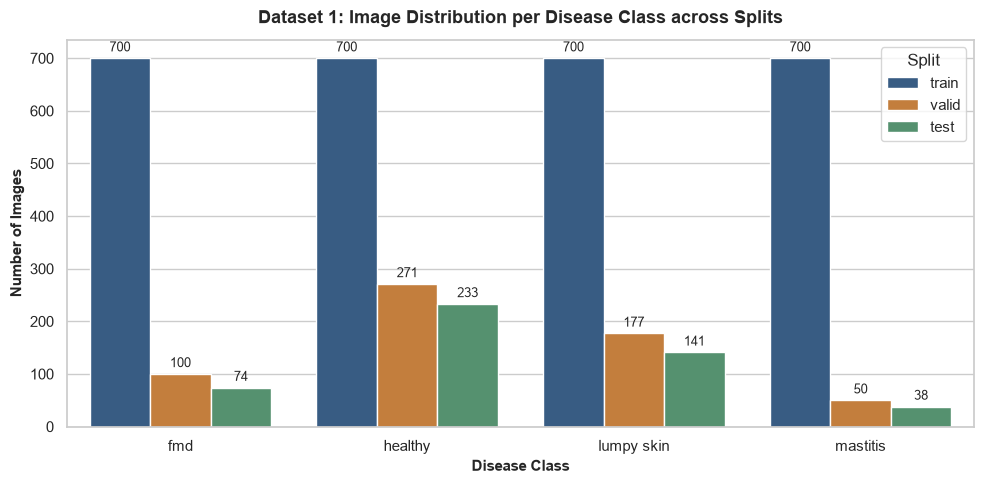

In [3]:
plt.figure(figsize=(10, 5))
split_order = ['train', 'valid', 'test']
palette = {'train': '#2b5c8f', 'valid': '#d97d27', 'test': '#4b9b6e'}

ax = sns.countplot(
    data=df_images,
    x='class',
    hue='split',
    hue_order=[s for s in split_order if s in df_images['split'].unique()],
    palette=palette
)

plt.title("Dataset 1: Image Distribution per Disease Class across Splits", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Disease Class", fontsize=11, fontweight='bold')
plt.ylabel("Number of Images", fontsize=11, fontweight='bold')
plt.legend(title="Split")

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{int(height)}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()


In [4]:
readable_images = []
unreadable_files = []
content_hashes = {}
duplicate_pairs = []

for idx, row in df_images.iterrows():
    fpath = row['filepath']
    
    try:
        with Image.open(fpath) as img:
            img.verify()
        readable_images.append(row)
    except Exception as e:
        unreadable_files.append({'filepath': fpath, 'error': str(e), 'size_bytes': row['size_bytes']})
        
    try:
        with open(fpath, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        if file_hash in content_hashes:
            duplicate_pairs.append({'duplicate_file': fpath, 'original_file': content_hashes[file_hash], 'hash': file_hash})
        else:
            content_hashes[file_hash] = fpath
    except Exception:
        pass

df_readable = pd.DataFrame(readable_images)
df_unreadable = pd.DataFrame(unreadable_files)

print("=== Image Quality & Integrity Audit Summary ===")
print(f"Total Files Indexed          : {len(df_images)}")
print(f"Fully Readable Image Files   : {len(df_readable)}")
print(f"Unreadable / Pointer Files   : {len(df_unreadable)}")
print(f"Exact Duplicate File Hashes  : {len(duplicate_pairs)}")

if len(df_unreadable) > 0:
    sample_stub_path = df_unreadable.iloc[0]['filepath']
    with open(sample_stub_path, 'r', errors='ignore') as f:
        stub_header = f.read(120).strip()
    print(f"\nAudit Note: Unreadable files are Git LFS pointer stubs (~{df_unreadable['size_bytes'].median():.0f} bytes).")
    print(f"Sample pointer content:\n\"{stub_header}\"")


=== Image Quality & Integrity Audit Summary ===
Total Files Indexed          : 3884
Fully Readable Image Files   : 2
Unreadable / Pointer Files   : 3882
Exact Duplicate File Hashes  : 23

Audit Note: Unreadable files are Git LFS pointer stubs (~129 bytes).
Sample pointer content:
"version https://git-lfs.github.com/spec/v1
oid sha256:130d384825680784bb3ad08200fc641da4b3229c2aeea26263e09320ffcee9bc
s"


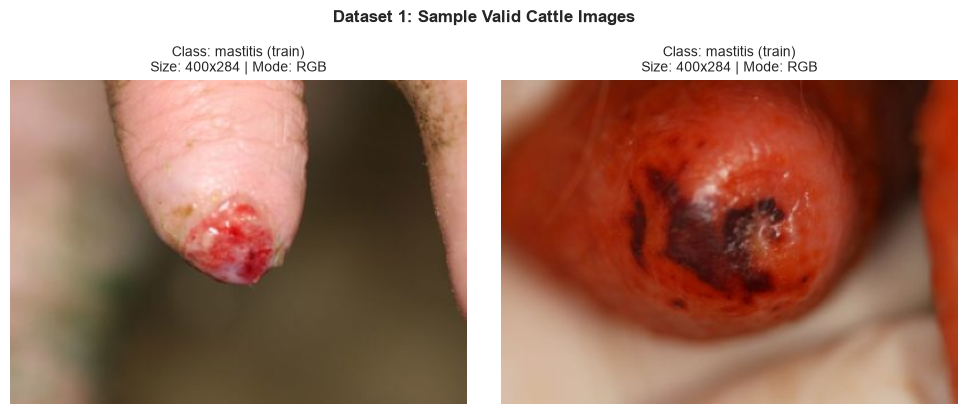

In [5]:
if len(df_readable) > 0:
    fig, axes = plt.subplots(1, min(len(df_readable), 2), figsize=(10, 4))
    if len(df_readable) == 1:
        axes = [axes]
    
    for i, (_, row) in enumerate(df_readable.head(2).iterrows()):
        img = Image.open(row['filepath'])
        axes[i].imshow(img)
        axes[i].set_title(f"Class: {row['class']} ({row['split']})\nSize: {img.size[0]}x{img.size[1]} | Mode: {img.mode}", fontsize=10)
        axes[i].axis('off')
    
    plt.suptitle("Dataset 1: Sample Valid Cattle Images", fontsize=12, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()
else:
    print("No valid raster image files found to render.")


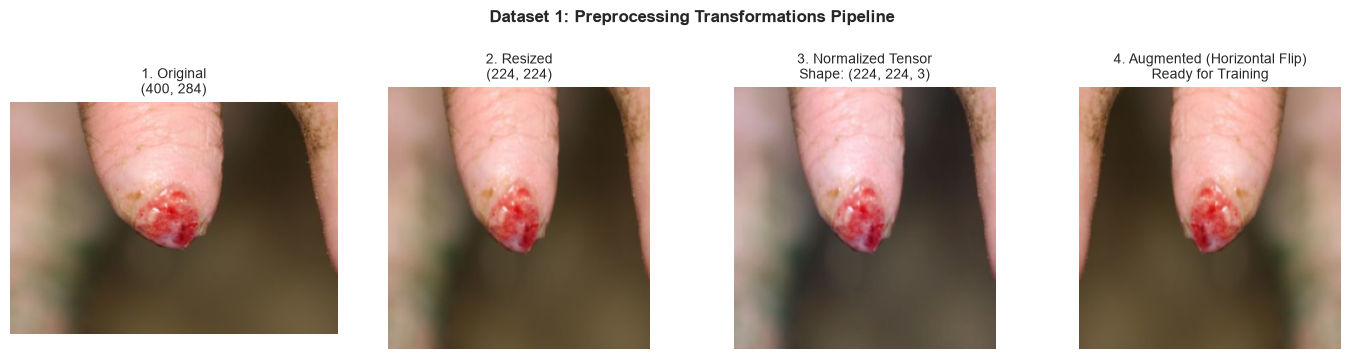

Preprocessing function verified: successfully resized, converted to RGB, normalized, and augmented.


In [6]:
def preprocess_cattle_image(image_path, target_size=(224, 224)):
    """
    Standard Computer Vision Preprocessing:
    1. Load image and ensure RGB mode.
    2. Resize to target dimension (e.g., 224x224 for CNN backbones).
    3. Scale pixel values to [0, 1].
    4. Normalize using standard ImageNet mean and std.
    """
    img = Image.open(image_path).convert('RGB')
    
    img_resized = img.resize(target_size, Image.Resampling.BILINEAR)
    
    img_array = np.array(img_resized, dtype=np.float32) / 255.0
    
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    img_normalized = (img_array - mean) / std
    
    img_augmented = ImageOps.mirror(img_resized)
    
    return img, img_resized, img_normalized, img_augmented

if len(df_readable) > 0:
    sample_path = df_readable.iloc[0]['filepath']
    orig, resized, norm, augmented = preprocess_cattle_image(sample_path)
    
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
    axes[0].imshow(orig)
    axes[0].set_title(f"1. Original\n{orig.size}", fontsize=10)
    axes[0].axis('off')
    
    axes[1].imshow(resized)
    axes[1].set_title(f"2. Resized\n{resized.size}", fontsize=10)
    axes[1].axis('off')
    
    norm_vis = np.clip((norm - norm.min()) / (norm.max() - norm.min()), 0, 1)
    axes[2].imshow(norm_vis)
    axes[2].set_title(f"3. Normalized Tensor\nShape: {norm.shape}", fontsize=10)
    axes[2].axis('off')
    
    axes[3].imshow(augmented)
    axes[3].set_title("4. Augmented (Horizontal Flip)\nReady for Training", fontsize=10)
    axes[3].axis('off')
    
    plt.suptitle("Dataset 1: Preprocessing Transformations Pipeline", fontsize=12, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    print("Preprocessing function verified: successfully resized, converted to RGB, normalized, and augmented.")


## 3. Cattle symptom dataset

Here we inspect the symptom CSV, check missing and duplicate records, look at disease and symptom frequencies, and prepare the feature matrix and target. The original `source_split` values are kept when making the train and test subsets.

In [7]:
df_symptoms = pd.read_csv(SYMPTOM_CSV_PATH)

print("Dataset 2 — Cattle Symptom Master Dataset:")
print(f"Total Rows (Records)    : {df_symptoms.shape[0]}")
print(f"Total Columns (Features): {df_symptoms.shape[1]}")

print("\nFirst 3 Records (Subset of Columns):")
display(df_symptoms[['anorexia', 'blisters', 'fever', 'udder_swelling', 'prognosis', 'source_split']].head(3))

dtype_counts = df_symptoms.dtypes.value_counts()
print(f"\nColumn Data Types breakdown:\n{dtype_counts}")


Dataset 2 — Cattle Symptom Master Dataset:
Total Rows (Records)    : 2070
Total Columns (Features): 95

First 3 Records (Subset of Columns):


,anorexia,blisters,fever,udder_swelling,prognosis,source_split
0,0,0,1,0,mastitis,train
1,0,0,1,0,mastitis,train
2,0,0,0,1,mastitis,train



Column Data Types breakdown:
int64    93
str       2
Name: count, dtype: int64


In [8]:
missing_total = df_symptoms.isna().sum().sum()
duplicate_rows = df_symptoms.duplicated().sum()

symptom_features = [col for col in df_symptoms.columns if col not in ['prognosis', 'source_split']]
duplicate_symptom_profiles = df_symptoms.duplicated(subset=symptom_features).sum()

print("=== Dataset 2 Data Quality Audit ===")
print(f"Total Missing Values (NaN)           : {missing_total}")
print(f"Exact Duplicate Rows                 : {duplicate_rows}")
print(f"Duplicate Symptom Feature Vectors    : {duplicate_symptom_profiles}")
print("\nClinical Context Note: In symptom-disease diagnosis matrices, multiple animal cases often present")
print("the same core binary symptom combination. Keeping these rows preserves empirical disease frequency.")


=== Dataset 2 Data Quality Audit ===
Total Missing Values (NaN)           : 0
Exact Duplicate Rows                 : 1611
Duplicate Symptom Feature Vectors    : 1622

Clinical Context Note: In symptom-disease diagnosis matrices, multiple animal cases often present
the same core binary symptom combination. Keeping these rows preserves empirical disease frequency.


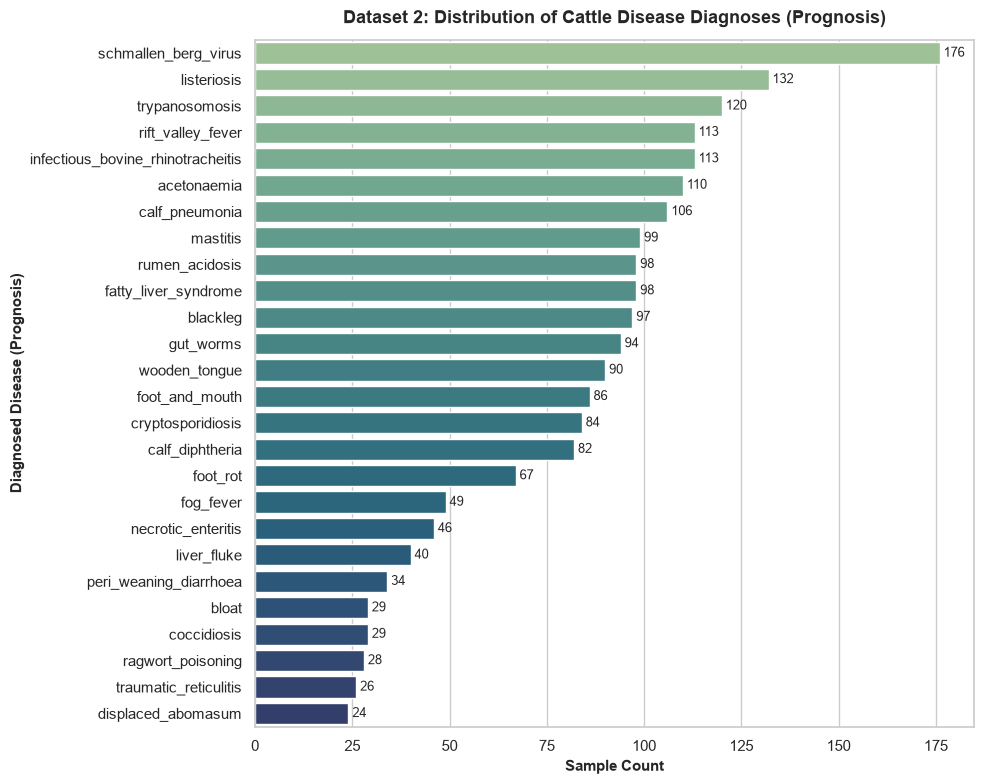

Total Unique Diseases Diagnosed: 26


In [9]:
plt.figure(figsize=(10, 8))
prognosis_counts = df_symptoms['prognosis'].value_counts()

sns.barplot(x=prognosis_counts.values, y=prognosis_counts.index, palette='crest')
plt.title("Dataset 2: Distribution of Cattle Disease Diagnoses (Prognosis)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Sample Count", fontsize=11, fontweight='bold')
plt.ylabel("Diagnosed Disease (Prognosis)", fontsize=11, fontweight='bold')

for i, count in enumerate(prognosis_counts.values):
    plt.text(count + 1, i, str(count), va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"Total Unique Diseases Diagnosed: {df_symptoms['prognosis'].nunique()}")


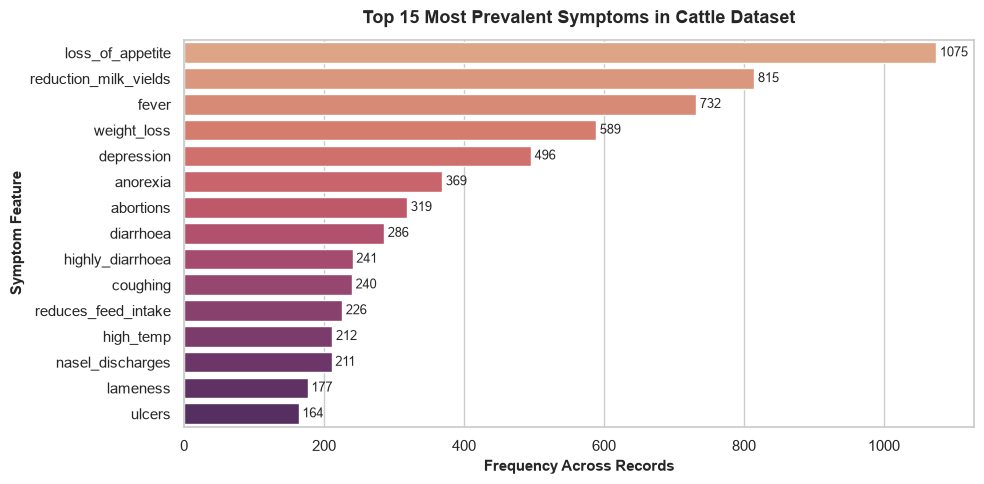

Key Distinguishing Symptoms for Sample Diseases:
 - mastitis: loss_of_appetite (60%), udder_redness (59%), fever (57%), depression (56%)
 - foot_and_mouth: blisters (80%), weight_loss (77%), fever (74%), reduction_milk_vields (72%)


In [10]:
symptom_sums = df_symptoms[symptom_features].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=symptom_sums.head(15).values, y=symptom_sums.head(15).index, palette='flare')
plt.title("Top 15 Most Prevalent Symptoms in Cattle Dataset", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Frequency Across Records", fontsize=11, fontweight='bold')
plt.ylabel("Symptom Feature", fontsize=11, fontweight='bold')

for i, count in enumerate(symptom_sums.head(15).values):
    plt.text(count + 5, i, str(int(count)), va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("Key Distinguishing Symptoms for Sample Diseases:")
for disease in ['mastitis', 'foot_and_mouth']:
    subset = df_symptoms[df_symptoms['prognosis'] == disease][symptom_features]
    top_syms = subset.mean().sort_values(ascending=False).head(4)
    sym_list = [f"{k} ({v*100:.0f}%)" for k, v in top_syms.items() if v > 0]
    print(f" - {disease}: {', '.join(sym_list)}")


In [11]:
X = df_symptoms[symptom_features]
y = df_symptoms['prognosis']
split_series = df_symptoms['source_split']

train_mask = (split_series == 'train')
test_mask = (split_series == 'test')

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("=== Feature Matrix & Target Preparation Summary ===")
print(f"Total Features (Symptom Indicators) : {X.shape[1]}")
print(f"Full Dataset Shape                   : X={X.shape}, y={y.shape}")
print(f"Train Split Shape                    : X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test Split Shape                     : X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Unique Diseases in Train Split       : {y_train.nunique()}")
print(f"Unique Diseases in Test Split        : {y_test.nunique()}")


=== Feature Matrix & Target Preparation Summary ===
Total Features (Symptom Indicators) : 93
Full Dataset Shape                   : X=(2070, 93), y=(2070,)
Train Split Shape                    : X_train=(2044, 93), y_train=(2044,)
Test Split Shape                     : X_test=(26, 93), y_test=(26,)
Unique Diseases in Train Split       : 26
Unique Diseases in Test Split        : 26


## 4. First-aid knowledge base

This section checks the guidance CSV for missing values and duplicate rows, then summarizes the conditions covered and their veterinary review status.

In [12]:
df_first_aid = pd.read_csv(FIRST_AID_CSV_PATH)

print("Dataset 3 — Cattle First-Aid Guidance Knowledge Base:")
print(f"Total Conditions (Rows) : {df_first_aid.shape[0]}")
print(f"Total Columns           : {df_first_aid.shape[1]}")

print("\nDataset Schema and Missing Values Check:")
missing_kb = df_first_aid.isna().sum()
schema_df = pd.DataFrame({
    'Column Name': df_first_aid.columns,
    'Data Type': df_first_aid.dtypes.astype(str),
    'Missing Values': missing_kb.values
})
display(schema_df)


Dataset 3 — Cattle First-Aid Guidance Knowledge Base:
Total Conditions (Rows) : 42
Total Columns           : 12

Dataset Schema and Missing Values Check:


,Column Name,Data Type,Missing Values
record_id,record_id,str,0
condition_name,condition_name,str,0
common_symptoms,common_symptoms,str,0
possible_causes,possible_causes,str,0
safe_first_aid,safe_first_aid,str,0
emergency_signs,emergency_signs,str,0
when_to_contact_vet,when_to_contact_vet,str,0
prevention,prevention,str,0
source_document,source_document,str,0
source_page,source_page,str,0


In [13]:
exact_duplicates_kb = df_first_aid.duplicated().sum()
print(f"Exact Duplicate Records Found: {exact_duplicates_kb}")

df_first_aid_cleaned = df_first_aid.drop_duplicates().copy()
print(f"Cleaned Knowledge Base Shape : {df_first_aid_cleaned.shape}")


Exact Duplicate Records Found: 0
Cleaned Knowledge Base Shape : (42, 12)


Total Unique Conditions Covered: 42
Sample Covered Conditions: ['Anthrax (suspected)', 'Bovine respiratory disease', 'Bovine viral diarrhoea (pestivirus)', "Johne's disease", 'Clostridial disease / enterotoxaemia']


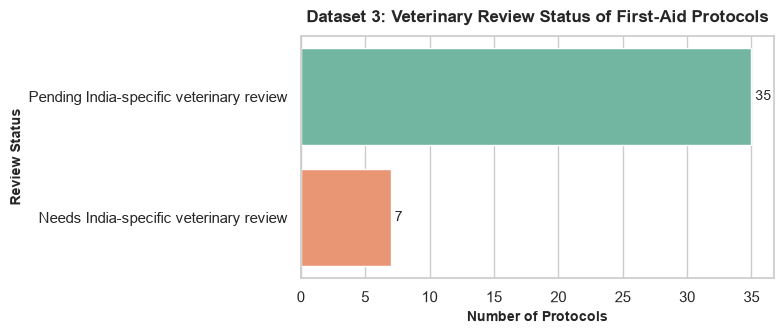


Sample PashuCare First-Aid Protocol Card:
Condition Name       : Anthrax (suspected)
Common Symptoms      : Sudden death; rapidly worsening weakness/staggering; bloody or tarry discharge may occur
Safe First-Aid       : Keep people and animals away; do not open or handle carcass; urgently call veterinarian/animal-health authority
Emergency Signs      : Unexplained sudden death or suspected anthrax
When to Contact Vet  : Immediately
Review Status        : Pending India-specific veterinary review


In [14]:
print(f"Total Unique Conditions Covered: {df_first_aid_cleaned['condition_name'].nunique()}")
print(f"Sample Covered Conditions: {list(df_first_aid_cleaned['condition_name'].head(5))}")

plt.figure(figsize=(8, 3.5))
review_counts = df_first_aid_cleaned['veterinary_review_status'].value_counts()
ax = sns.barplot(x=review_counts.values, y=review_counts.index, palette='Set2')
plt.title("Dataset 3: Veterinary Review Status of First-Aid Protocols", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Number of Protocols", fontsize=10, fontweight='bold')
plt.ylabel("Review Status", fontsize=10, fontweight='bold')

for i, count in enumerate(review_counts.values):
    plt.text(count + 0.3, i, str(count), va='center', fontsize=10)

plt.tight_layout()
plt.show()

print("\nSample PashuCare First-Aid Protocol Card:")
sample_card = df_first_aid_cleaned.iloc[0]
print(f"Condition Name       : {sample_card['condition_name']}")
print(f"Common Symptoms      : {sample_card['common_symptoms']}")
print(f"Safe First-Aid       : {sample_card['safe_first_aid']}")
print(f"Emergency Signs      : {sample_card['emergency_signs']}")
print(f"When to Contact Vet  : {sample_card['when_to_contact_vet']}")
print(f"Review Status        : {sample_card['veterinary_review_status']}")


## 5. Summary

- **Image dataset:** Indexed image files by class and split, checked file readability and exact duplicates, and demonstrated RGB conversion, resizing, normalization, and a horizontal flip.
- **Symptom dataset:** Checked the records and symptom columns, reviewed disease and symptom counts, and prepared `X` and `y` using the existing split labels.
- **First-aid knowledge base:** Reviewed the schema, checked missing values and duplicate rows, and summarized the conditions and review statuses.

These steps provide an initial data-quality overview. The results should be checked again whenever the source datasets change.